# Support Vector Machines
**Name:** GUNTI RAHUL |  **Roll No:** CH.SC.U4CSE24211 
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 8.6

## Exercise 1 - SVM on quadratic data
Generate points scattered around a parabola and label them by whether they fall above or below it. A straight line cannot separate them, so we compare kernels.

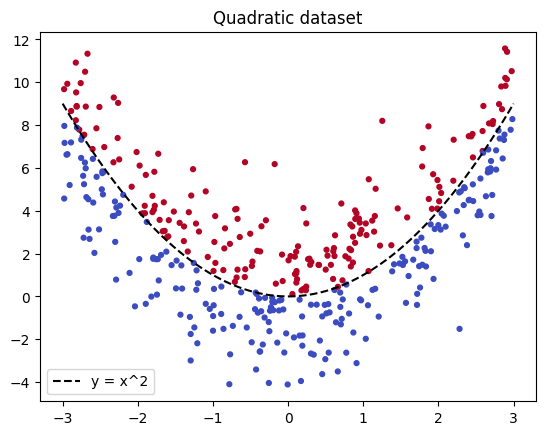

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

r = np.random.default_rng(262); x = r.uniform(-3, 3, 400)
y = x ** 2 + r.normal(0, 2, 400)
label = (y > x ** 2).astype(int); X = np.c_[x, y]
plt.scatter(x, y, c=label, s=12, cmap="coolwarm"); xs = np.linspace(-3, 3, 100); plt.plot(xs, xs ** 2, "k--", label="y = x^2")
plt.legend(); plt.title("Quadratic dataset"); plt.show()

In [2]:
Xtr, Xte, ytr, yte = train_test_split(X, label, test_size=.25, random_state=262, stratify=label)
rows = []
for k, kw in [("linear", {}), ("poly", {"degree": 2}), ("poly", {"degree": 3}), ("rbf", {})]:
    m = make_pipeline(StandardScaler(), SVC(kernel=k, **kw)).fit(Xtr, ytr)
    rows.append((f"{k} {kw}", round(m.score(Xtr, ytr), 3), round(m.score(Xte, yte), 3)))
pd.DataFrame(rows, columns=["kernel", "train_acc", "test_acc"])

,kernel,train_acc,test_acc
0,linear {},0.650,0.60
1,poly {'degree': 2},0.587,0.53
2,poly {'degree': 3},0.773,0.75
3,rbf {},0.950,0.94


In [3]:
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC()), {"svc__kernel": ["rbf", "poly"], "svc__C": [.1, 1, 10, 100], "svc__gamma": ["scale", .1, 1]}, cv=5)
grid.fit(Xtr, ytr); print("Best params:", grid.best_params_, "| CV acc:", round(grid.best_score_, 3))
best = grid.best_estimator_; pred = best.predict(Xte)
print("Test accuracy:", round(accuracy_score(yte, pred), 3)); print(classification_report(yte, pred))
svc = best.named_steps["svc"]; print("Support vectors per class:", svc.n_support_)

Best params: {'svc__C': 100, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'} | CV acc: 0.973
Test accuracy: 0.95
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        55
           1       0.92      0.98      0.95        45

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100

Support vectors per class: [15 14]


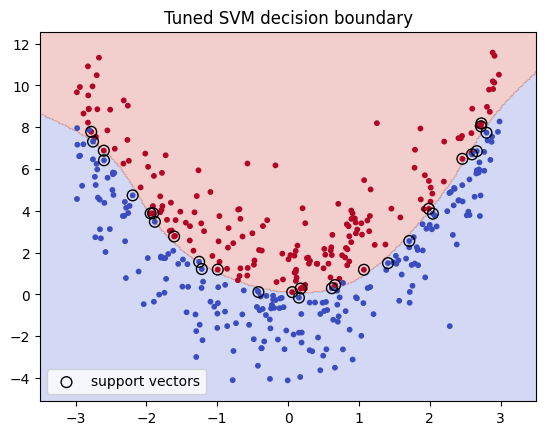

In [4]:
gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 300), np.linspace(y.min() - 1, y.max() + 1, 300))
zz = best.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
plt.contourf(gx, gy, zz, alpha=.25, cmap="coolwarm"); plt.scatter(X[:, 0], X[:, 1], c=label, s=10, cmap="coolwarm")
sv = best.named_steps["standardscaler"].inverse_transform(svc.support_vectors_)
plt.scatter(sv[:, 0], sv[:, 1], s=60, facecolors="none", edgecolors="k", label="support vectors"); plt.legend()
plt.title("Tuned SVM decision boundary"); plt.show()

## Exercise 2 - Spam vs not-spam
Each email is described by two features: frequency of spammy words and message length (characters).

      word_freq   length
spam                    
0         0.030  188.353
1         0.121  356.654


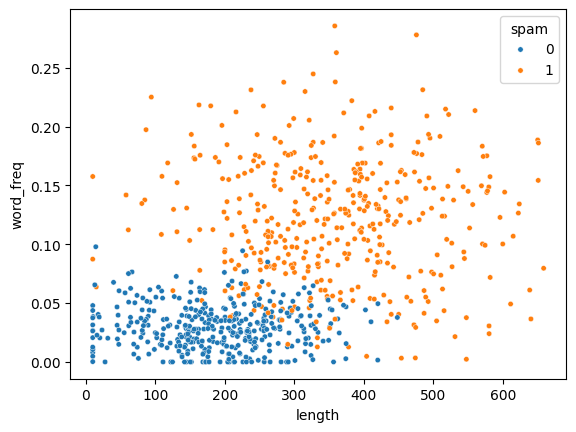

In [5]:
n = 800; r = np.random.default_rng(262); spam = r.integers(0, 2, n)
mail = pd.DataFrame({
    "word_freq": np.where(spam == 1, r.normal(.12, .05, n), r.normal(.03, .02, n)).clip(0),
    "length": np.where(spam == 1, r.normal(350, 120, n), r.normal(180, 90, n)).clip(10), "spam": spam})
print(mail.groupby("spam").mean().round(3))
sns.scatterplot(data=mail, x="length", y="word_freq", hue="spam", s=15); plt.show()

Best: {'svc__C': 0.1, 'svc__kernel': 'rbf'}
              precision    recall  f1-score   support

    not spam       0.95      0.97      0.96        96
        spam       0.97      0.95      0.96       104

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



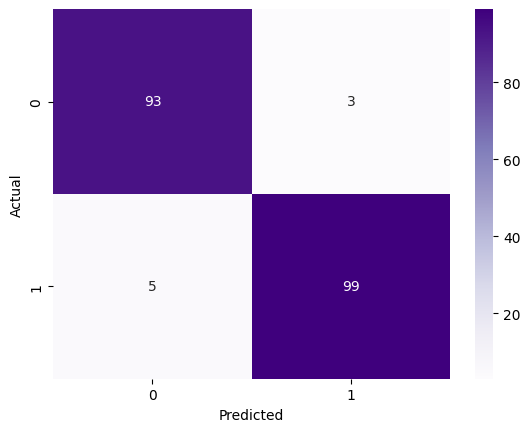

,word_freq,length,P(spam),label
0,0.15,400,0.992,1
1,0.02,120,0.015,0


In [6]:
Xm, ym = mail[["word_freq", "length"]], mail["spam"]
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xm, ym, test_size=.25, random_state=262, stratify=ym)
sp = GridSearchCV(make_pipeline(StandardScaler(), SVC(probability=True)), {"svc__kernel": ["linear", "rbf"], "svc__C": [.1, 1, 10]}, cv=5).fit(Xtr2, ytr2)
print("Best:", sp.best_params_); p = sp.predict(Xte2)
print(classification_report(yte2, p, target_names=["not spam", "spam"]))
sns.heatmap(confusion_matrix(yte2, p), annot=True, fmt="d", cmap="Purples"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
new = pd.DataFrame({"word_freq": [.15, .02], "length": [400, 120]})
new["P(spam)"] = sp.predict_proba(new)[:, 1].round(3); new["label"] = sp.predict(new[["word_freq", "length"]]); new

### Conclusion
A linear kernel misses the curved boundary, while polynomial/RBF kernels fit it. Grid search over `C` and `gamma` balances margin width against training errors, and only the support vectors define the final boundary.